In [169]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [170]:
def lagrange_interpolation(x_values, y_values):
  """
  Compute the Lagrange Interpolating Polynomial for given data points.

  Parameters:
    x_values (list or array): x-coordinates of data points
    y_values (list or array): y-coordinates of data points

  Returns:
    polynomial (sympy expression): The Lagrange Polynomial
  """
  x = sp.Symbol('x')
  n = len(x_values)
  L = 0
  for i in range(n):
    term = y_values[i]
    for j in range(n):
      if i != j:
        term *= (x - x_values[j]) / (x_values[i] - x_values[j])
    L += term
  return sp.simplify(L)

In [171]:
def plot_lagrange(x_values, y_values, polynomial, x_interp=None):
  """
  Plot the Lagrange Interpolating Polynomial along with the data points and an interpolated value.

  Parameters:
    x_values (list or array): x-coordinates of data points
    y_values (list or array): y-coordinates of data points
    polynomial (sympy expression): The Lagrange Polynomial
    x_interp (float/optional): The x value at which to evaluate the polynomial
  """
  x = sp.Symbol('x')
  f_lambdified = sp.lambdify(x, polynomial, 'numpy')
  x_plot = np.linspace(min(x_values)-1, max(x_values)+1, 500)
  y_plot = f_lambdified(x_plot)
  plt.plot(x_plot, y_plot, label="Lagrange Polynomial", color='blue')
  plt.scatter(x_values, y_values, color='red', label='Data Points', zorder=3)
  if x_interp is not None:
    y_interp = f_lambdified(x_interp)
    plt.scatter([x_interp], [y_interp], color='green', marker='o', s=100, label=f'Interpolated ({x_interp}, {y_interp:.2f})')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.title('Lagrange Interpolating Polynomial')
  plt.legend()
  plt.grid(True)
  plt.show()
  return y_interp if x_interp is not None else None

In [172]:
# Example Usage
x_vals = [1, 2, 3, 4, 6, 8, 10, 11, 15, 20]
y_vals = [0, 4, 5, 8, 10, 12, 12, 5, 3, 10]
# x_vals = [0.1745, 0.3491, 0.5236]
# y_vals = [1.1585, 1.2817, 1.3660]
# x_vals = [-2, -1, 1, 3, 4]
# y_vals = [9, 16, 18, 44, 81]

In [173]:
poly = lagrange_interpolation(x_vals, y_vals)
print("Lagrange Interpolating Polynomial")
sp.pprint(poly)    # Pretty Print the polynomial

Lagrange Interpolating Polynomial
          9            8             7               6                 5       ↪
 1226899⋅x     131497⋅x    49634579⋅x    3752755859⋅x    252147242027⋅x    114 ↪
──────────── - ───────── + ─────────── - ───────────── + ─────────────── - ─── ↪
502831929600   644656320   6983776800     27935107200     167610643200       1 ↪

↪           4                  3                 2                          
↪ 49118267⋅x    5272492423613⋅x    294001033901⋅x    41817507013⋅x   2063437
↪ ─────────── + ──────────────── - ─────────────── + ───────────── - ───────
↪ 117404288       125707982400       2993047200        349188840      37791 


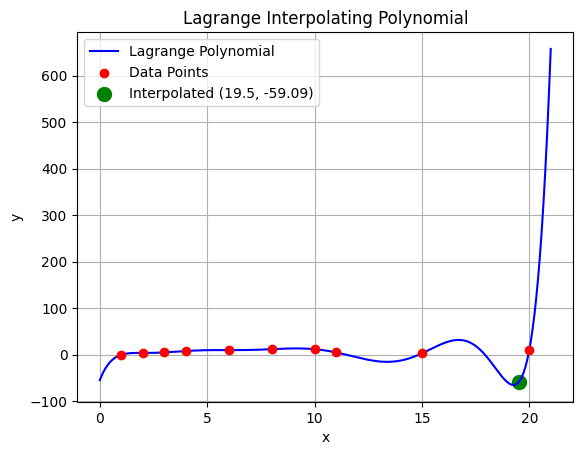

In [174]:
# Define the point to interpolate
x_interp_val = 19.5
y_interp_val = plot_lagrange(x_vals, y_vals, poly, x_interp_val)

In [175]:
print(f"\nInterpolated value at x = {x_interp_val}: y = {y_interp_val:.2f}")


Interpolated value at x = 19.5: y = -59.09
